# Notebook for Section 4.3.3. Classification Across Mixed Coding Regimes

In [5]:
from utils import *

# Code to generate mixed-regime datasets

In [2]:
def generate_hybrid_dataset(n_neurons=1000, rate_percent=0.20, corr_percent=0.50, noise_percent=0.30, 
                            n_trials=30, time_bins=2000, random_state=None):
    """
    Generates a hybrid dataset of 1000 neurons mixing Rate Coding, correlation Coding, and Noise.
    
    Parameters:
    - rate_percent: Fraction of neurons dedicated to independent rate coding.
    - corr_percent: Fraction of neurons dedicated to flat-rate correlation coding.
    - noise_percent: Fraction of neurons that are pure background noise (fixed at 0.30).
    """
    
    if random_state is not None:
        np.random.seed(random_state)
    
    # 1. Validate percentages
    total_percent = rate_percent + corr_percent + noise_percent
    if not np.isclose(total_percent, 1.0):
        raise ValueError(f"Percentages must sum to 1.0. Currently sum to {total_percent}")
        
    # 2. Allocate Neurons to Pools
    n_rate = int(n_neurons * rate_percent)
    n_corr = int(n_neurons * corr_percent)
    n_noise = n_neurons - n_rate - n_corr # catches any rounding remainder
    
    # 3. Define Probabilities
    p_bg = 0.015       # Background noise
    p_corr = 0.010     # Mother signal strength
    p_baseline = 0.015 # Baseline for quiet rate-coders
    p_elevated = 0.025 # Loud rate for target rate-coders
    
    X, y = [], []
    
    for taste in [0, 1, 2]:
        for _ in range(n_trials):
            raster = np.zeros((n_neurons, time_bins), dtype=int)
            
            # ==========================================
            # POOL A: Independent Rate Coding
            # ==========================================
            if n_rate > 0:
                # Split the rate pool into 3 chunks (one for each taste)
                chunk_size = n_rate // 3
                
                for i in range(n_rate):
                    # Determine if this neuron is in the "loud" chunk for the current taste
                    if (taste == 0 and i < chunk_size) or \
                       (taste == 1 and chunk_size <= i < 2 * chunk_size) or \
                       (taste == 2 and i >= 2 * chunk_size):
                        p = p_elevated
                    else:
                        p = p_baseline
                        
                    raster[i] = np.random.binomial(1, p, time_bins)
                    
            # ==========================================
            # POOL B: Correlation Coding (Flat Rate)
            # ==========================================
            if n_corr > 0:
                corr_offset = n_rate # Starting index for Pool B
                
                # First, give all Pool B neurons their independent background noise
                for i in range(corr_offset, corr_offset + n_corr):
                    raster[i] = np.random.binomial(1, p_bg, time_bins)
                    
                # Class 0: Broad correlation (The Hub)
                if taste == 0:
                    mother = np.random.binomial(1, p_corr, time_bins)
                    # corr the first half of the pool to the mother
                    half_corr = n_corr // 2
                    for i in range(corr_offset, corr_offset + half_corr):
                        raster[i] = np.logical_or(raster[i], mother)
                    # The other half gets independent dummy trains to keep rates flat
                    for i in range(corr_offset + half_corr, corr_offset + n_corr):
                        dummy = np.random.binomial(1, p_corr, time_bins)
                        raster[i] = np.logical_or(raster[i], dummy)
                        
                # Class 1: Localized correlation (The Clusters/Pairs)
                elif taste == 1:
                    cluster_size = 5 # Small groups of neurons firing together
                    for i in range(corr_offset, corr_offset + n_corr, cluster_size):
                        mother = np.random.binomial(1, p_corr, time_bins)
                        # Apply this local mother train to the small cluster
                        for j in range(i, min(i + cluster_size, corr_offset + n_corr)):
                            raster[j] = np.logical_or(raster[j], mother)
                            
                # Class 2: No correlation (Independent Flat Rate)
                elif taste == 2:
                    for i in range(corr_offset, corr_offset + n_corr):
                        dummy = np.random.binomial(1, p_corr, time_bins)
                        raster[i] = np.logical_or(raster[i], dummy)

            # ==========================================
            # POOL C: Pure Background Noise
            # ==========================================
            if n_noise > 0:
                noise_offset = n_rate + n_corr
                for i in range(noise_offset, n_neurons):
                    # Fixed at p_elevated volume to act as dense background clutter
                    raster[i] = np.random.binomial(1, p_elevated, time_bins)
                    
            X.append(raster)
            y.append(taste)
            
    return X, np.array(y)

# 100 Neurons

In [5]:
import time
rate_pct_list = [0.0, # 0 %
                 0.01, # 1%
                 0.02, # 2%
                 0.03, # 3%
                 0.04, # 4%
                 0.05, # 5%
                 0.1, # 10%
                 0.2, # 20%
                 0.3, # 30%
                 0.4, # 40%
                 0.5, # 50%
                 0.6, # 60%
                 ]



results = []
n_neurons = 100

for rate_pct in tqdm(rate_pct_list, desc="Running rate_pct experiments"):
    corr_pct = 0.70 - rate_pct
    print(f"\nGenerating mix -> Rate: {rate_pct*100:.1f}%, Correlation: {corr_pct*100:.1f}%")

    # Generate the data
    X, y = generate_hybrid_dataset(rate_percent=rate_pct, corr_percent=corr_pct, n_neurons = n_neurons, random_state = 42)

    # TDA Original
    print("  Running TDA...")
    tda_start = time.perf_counter()
    tda_acc = tda_rhv(X, y)
    tda_runtime = time.perf_counter() - tda_start
    print(f"  TDA done | Acc: {tda_acc:.4f} | Time: {tda_runtime:.2f} s")

    # SVM Pure Rate
    print("  Running SVM...")
    svm_start = time.perf_counter()
    svm_acc, _, _ = svm_smoothed_rasters(X, y)
    svm_runtime = time.perf_counter() - svm_start
    print(f"  SVM done | Acc: {svm_acc:.4f} | Time: {svm_runtime:.2f} s")

    # Save the results
    results.append({
        'Rate_Percent': rate_pct,
        'Corr_Percent': corr_pct,
        'TDA_Acc': tda_acc,
        'TDA_Runtime_Sec': tda_runtime,
        'SVM_Acc': svm_acc,
        'SVM_Runtime_Sec': svm_runtime
    })
    



Running rate_pct experiments:   0%|          | 0/12 [00:00<?, ?it/s]


Generating mix -> Rate: 0.0%, Correlation: 70.0%
  Running TDA...


Building BDM: 100%|██████████| 90/90 [00:00<00:00, 169.26it/s]


  TDA done | Acc: 0.9907 | Time: 6.82 s
  Running SVM...


Running rate_pct experiments:   8%|▊         | 1/12 [00:18<03:23, 18.46s/it]

  SVM done | Acc: 0.3463 | Time: 11.45 s

Generating mix -> Rate: 1.0%, Correlation: 69.0%
  Running TDA...


... (40 outputs left out)

Building BDM: 100%|██████████| 90/90 [00:00<00:00, 178.23it/s]


  TDA done | Acc: 0.3833 | Time: 6.17 s
  Running SVM...


Running rate_pct experiments: 100%|██████████| 12/12 [03:33<00:00, 17.81s/it]

  SVM done | Acc: 1.0000 | Time: 10.57 s


In [23]:
import pandas as pd
# save results
# df_results = pd.DataFrame(results)

# df_results.to_csv('hybrid_experiment_results_100_neurons.csv', index=False)

df_results = pd.read_csv('hybrid_experiment_results_100_neurons.csv')
df_results.head()

,Rate_Percent,Corr_Percent,TDA_Acc,TDA_Runtime_Sec,SVM_Acc,SVM_Runtime_Sec
0,0.00,0.70,0.990741,6.822971,0.346296,11.452294
1,0.01,0.69,0.985185,6.662940,0.437037,11.312157
2,0.02,0.68,0.970370,6.705080,0.566667,10.969147
3,0.03,0.67,0.966667,6.573060,0.714815,11.099592
4,0.04,0.66,0.929630,6.970837,0.738889,11.709439


# Plot Figure 7C

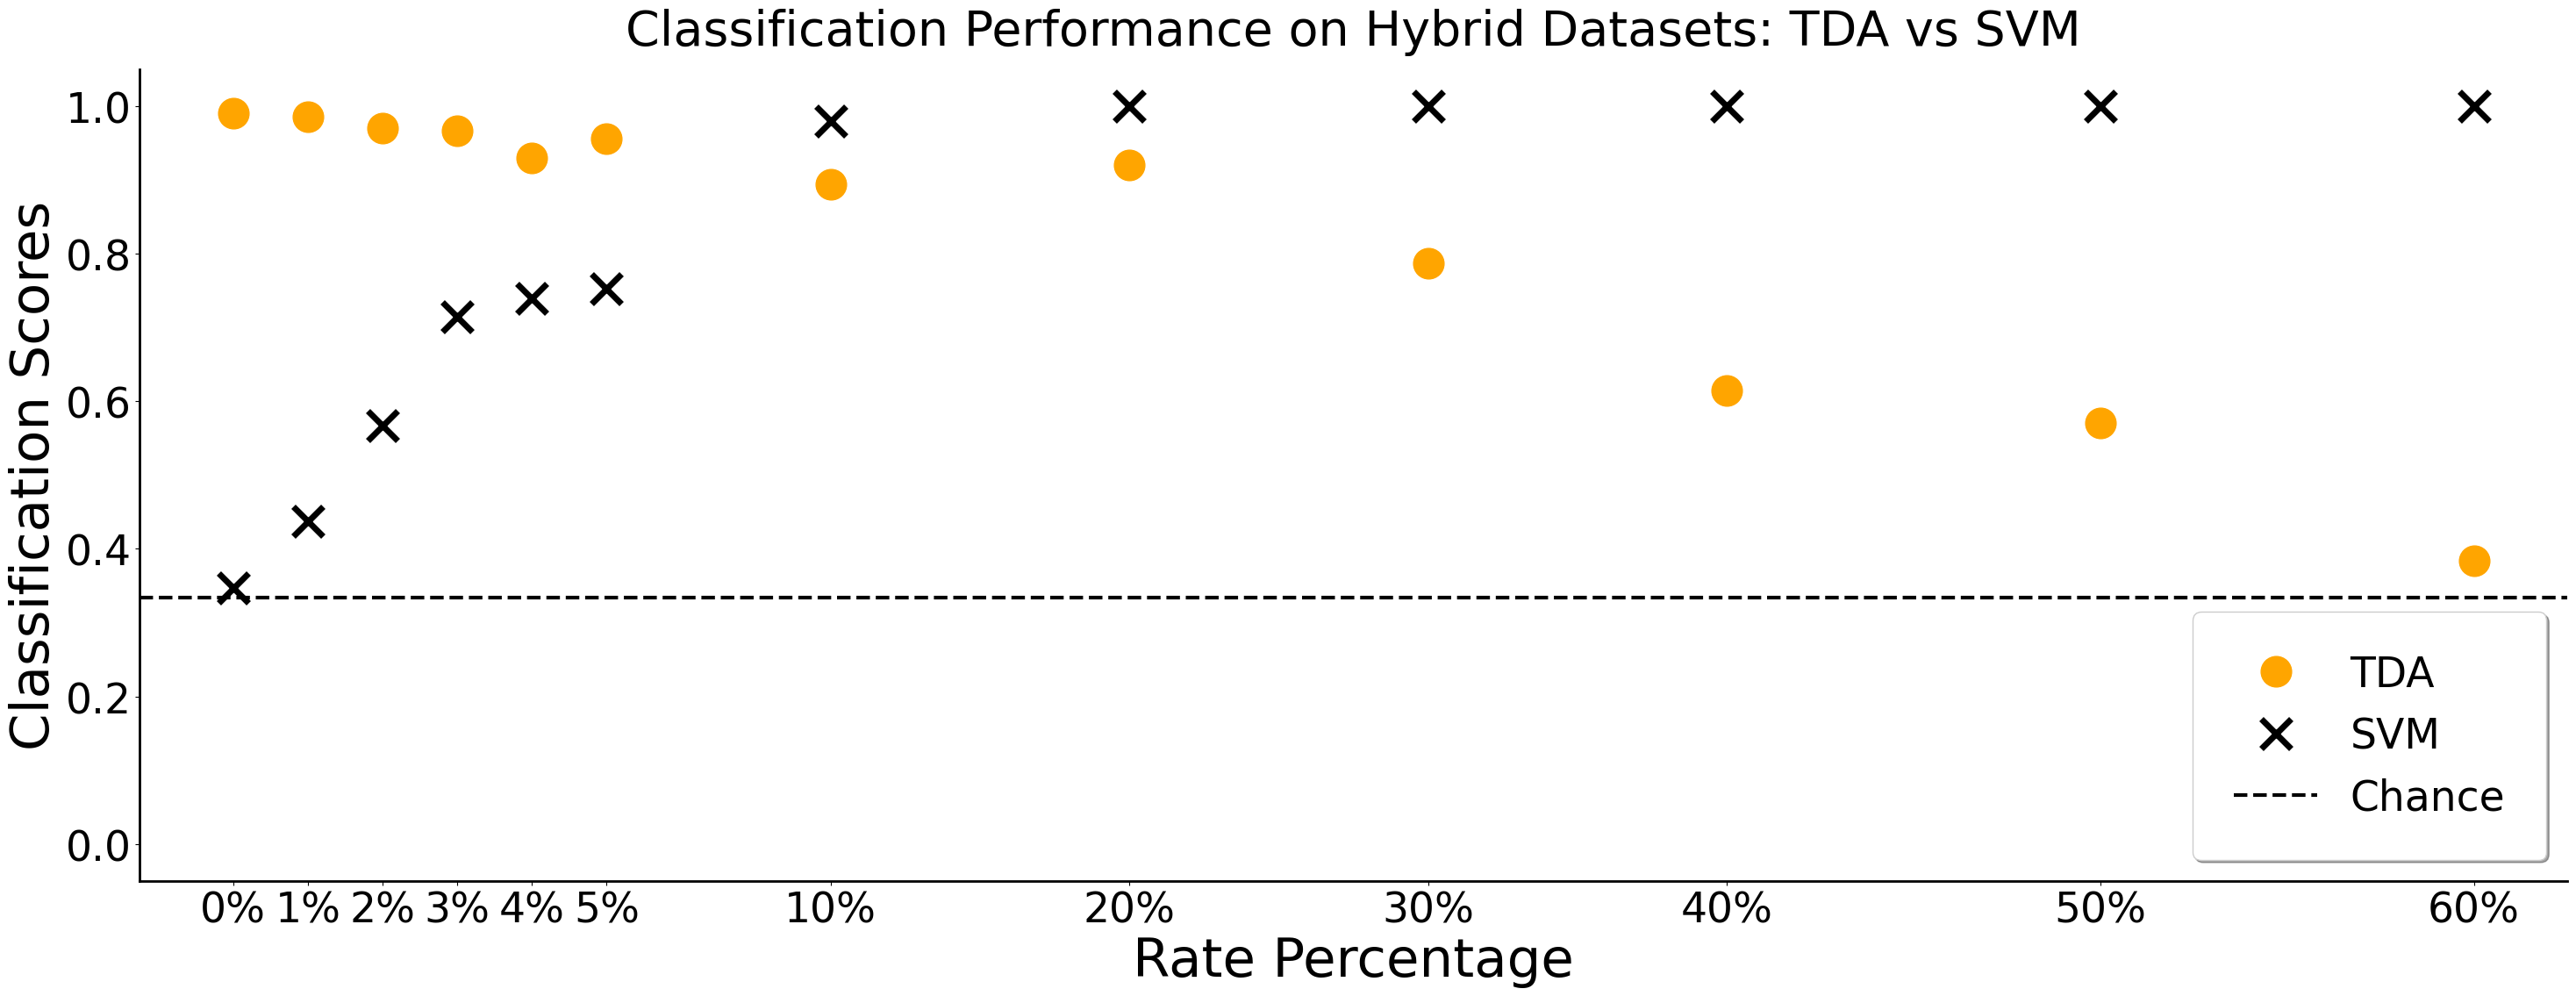

In [39]:
df_results = df_results.sort_values(by='Rate_Percent').reset_index(drop=True)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 28,
    'figure.titlesize': 40,
    'figure.titleweight': 'bold',
    'axes.titlesize': 40,
    'axes.titleweight': 'normal',
    'axes.labelsize': 44,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 34,
    'ytick.labelsize': 34,
    'legend.fontsize': 34,
    'legend.title_fontsize': 20,
    'axes.titlepad': 20
})

fig, ax = plt.subplots(figsize=(30, 12))

# Actual rate percentages
rate_vals = 100 * df_results['Rate_Percent'].to_numpy()

# ------------------------------------------------------------
# Manual x-position control
# ------------------------------------------------------------
# By default, each point is plotted at its actual percentage.
# Change these numbers to manually adjust horizontal placement.
#
# Example:
#   0% stays at 0
#   1% displayed at 2
#   2% displayed at 4
#   ...
# Labels will still show the original rate percentages.
# ------------------------------------------------------------

manual_x_positions = {
    0: 0,
    1: 2,
    2: 4,
    3: 6,
    4: 8,
    5: 10,
    10: 16,
    20: 24,
    30: 32,
    40: 40,
    50: 50,
    60: 60,
}

x_plot = np.array([
    manual_x_positions.get(int(round(r)), r)
    for r in rate_vals
])

# Plot TDA
ax.plot(
    x_plot,
    df_results['TDA_Acc'],
    'o',
    color='orange',
    label='TDA',
    markersize=25,
    clip_on=True
)

# Plot SVM
ax.plot(
    x_plot,
    df_results['SVM_Acc'],
    'x',
    color='black',
    label='SVM',
    markersize=25,
    mew=5,
    clip_on=True
)

# Chance line
ax.axhline(
    y=1/3,
    color='black',
    linestyle='--',
    lw=3,
    label='Chance'
)

# Tick labels: placed at manual positions, labeled by true rate percentages
ax.set_xticks(x_plot)
ax.set_xticklabels([f"{int(round(r))}%" for r in rate_vals], rotation=0)

# Add horizontal padding so boundary markers do not leak out
x_pad = 2.5
ax.set_xlim(x_plot.min() - x_pad, x_plot.max() + x_pad)

ax.set_xlabel("Rate Percentage")
ax.set_ylabel("Classification Scores")
ax.set_title("Classification Performance on Hybrid Datasets: TDA vs SVM")
ax.set_ylim(-0.05, 1.05)

ax.legend(loc='lower right', frameon=True, shadow=True, borderpad=1)
# ax.grid(True, linestyle='--', alpha=0.6, linewidth=1.5)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep left and bottom spines
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# Optional: make ticks only appear on left and bottom
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')



plt.tight_layout()
# plt.savefig('hybrid_datasets_tda_vs_svm_100_neurons.pdf')
plt.savefig('hybrid_datasets_tda_vs_svm_100_neurons_v2.pdf')
plt.show()

# Plot figure 7A and 7B

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.manifold import MDS

# --- Universal Font Controls ---
plt.rcParams.update({
    'axes.titlesize': 24,
    'axes.labelsize': 22,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 24,
    'axes.titlepad': 24
})


def format_percent(pct):
    """
    Format percentages without unnecessary decimals.

    Examples:
        0.35 -> '35%'
        0.305 -> '30.5%'
    """
    value = pct * 100
    if np.isclose(value, round(value)):
        return f"{int(round(value))}%"
    return f"{value:.1f}%"


def compute_raster_dot_size(n_neurons):
    """
    Adaptive raster marker size.

    Desired behavior:
        n_neurons = 100  -> size about 7-8
        n_neurons = 1000 -> size about 1
    """
    return float(np.clip(8 * (100 / n_neurons), 1.0, 8.0))


def compute_mds_dot_size(n_neurons):
    """
    Adaptive MDS marker size.

    Desired behavior:
        n_neurons = 100   -> about 50
        n_neurons = 1000  -> about 8-12
    """
    return float(np.clip(80 * (100 / n_neurons)**0.8, 6.0, 50.0))


def compute_rate_loud_regions(n_rate):
    """
    Compute elevated firing-rate regions dynamically.

    This matches the generation logic:

        chunk_size = n_rate // 3

        taste 0: i < chunk_size
        taste 1: chunk_size <= i < 2 * chunk_size
        taste 2: i >= 2 * chunk_size

    Returned neuron IDs are displayed IDs, so they start at 1.
    """

    if n_rate <= 0:
        return [None, None, None]

    chunk_size = n_rate // 3
    regions = []

    # Stim-1 / taste 0
    if chunk_size > 0:
        regions.append((1, chunk_size))
    else:
        regions.append(None)

    # Stim-2 / taste 1
    if chunk_size > 0:
        regions.append((chunk_size + 1, 2 * chunk_size))
    else:
        regions.append(None)

    # Stim-3 / taste 2, includes the remainder
    start_third = 2 * chunk_size + 1
    end_third = n_rate

    if start_third <= end_third:
        regions.append((start_third, end_third))
    else:
        regions.append(None)

    return regions


def get_dynamic_y_ticks(n_neurons):
    """
    Only show first and last neuron IDs.

    Examples:
        n_neurons = 100  -> [1, 100]
        n_neurons = 1000 -> [1, 1000]
    """
    if n_neurons <= 1:
        return [1]
    return [1, n_neurons]


def plot_raster_colored(
    raster,
    axes,
    n_rate,
    n_corr,
    n_noise,
    raster_marker='o',
    rate_color='blue',
    corr_color='red',
    noncoder_color='gray',
    rate_size=7,
    corr_size=7,
    noncoder_size=7,
    rate_alpha=1.0,
    corr_alpha=1.0,
    noncoder_alpha=1.0,
    loud_region=None,
    loud_region_color='blue',
    loud_region_alpha=0.10,
    loud_region_edge_alpha=0.35,
):
    """
    Colored raster plot.

    Neuron groups are assumed to be ordered as:
        1. Rate coders
        2. Correlation coders
        3. Non-coders
    """

    # Optional elevated firing-rate region highlight
    if loud_region is not None:
        start_neuron, end_neuron = loud_region

        axes.axhspan(
            start_neuron - 0.5,
            end_neuron + 0.5,
            color=loud_region_color,
            alpha=loud_region_alpha,
            zorder=1
        )

        axes.axhline(
            start_neuron - 0.5,
            color=loud_region_color,
            alpha=loud_region_edge_alpha,
            linewidth=1.5,
            linestyle='--',
            zorder=2
        )

        axes.axhline(
            end_neuron + 0.5,
            color=loud_region_color,
            alpha=loud_region_edge_alpha,
            linewidth=1.5,
            linestyle='--',
            zorder=2
        )

    group_specs = [
        {
            "name": "Rate Coders",
            "start": 0,
            "end": n_rate,
            "color": rate_color,
            "size": rate_size,
            "alpha": rate_alpha,
        },
        {
            "name": "Correlation Coders",
            "start": n_rate,
            "end": n_rate + n_corr,
            "color": corr_color,
            "size": corr_size,
            "alpha": corr_alpha,
        },
        {
            "name": "Non-coders",
            "start": n_rate + n_corr,
            "end": n_rate + n_corr + n_noise,
            "color": noncoder_color,
            "size": noncoder_size,
            "alpha": noncoder_alpha,
        },
    ]

    for spec in group_specs:
        start = spec["start"]
        end = spec["end"]

        if end <= start:
            continue

        subraster = raster[start:end]
        local_neuron_ids, spike_times = np.where(subraster == 1)

        # Convert internal 0-based neuron index to displayed 1-based neuron ID
        neuron_ids_displayed = local_neuron_ids + start + 1

        axes.scatter(
            spike_times,
            neuron_ids_displayed,
            s=spec["size"],
            c=spec["color"],
            marker=raster_marker,
            alpha=spec["alpha"],
            linewidths=0,
            edgecolors='none',
            zorder=3
        )

    axes.set_ylim(0.5, raster.shape[0] + 0.5)
    axes.set_xlim(0, raster.shape[1])
    axes.grid(True, axis='x', alpha=0.2, zorder=0)


def raster_MDS_plots(
    rate_pct,
    corr_pct,
    n_neurons=100,
    random_state=42,
    show_elevated_rate_region=False
):
    """
    Plot example rasters and MDS visualizations.

    Parameters
    ----------
    rate_pct : float
        Fraction of neurons that are rate coders.

    corr_pct : float
        Fraction of neurons that are correlation coders.

    n_neurons : int
        Total number of neurons.

    random_state : int
        Random seed.

    show_elevated_rate_region : bool
        If True, highlight the elevated firing-rate region.
        If False, no highlight is shown and no highlight legend entry is added.
    """

    n_rate = int(n_neurons * rate_pct)
    n_corr = int(n_neurons * corr_pct)
    n_noise = n_neurons - n_rate - n_corr
    noise_pct = n_noise / n_neurons

    raster_dot_size = compute_raster_dot_size(n_neurons)
    mds_dot_size = compute_mds_dot_size(n_neurons)

    print(f"Total Neurons: {n_neurons}")
    print(f" - Rate Coders (Blue):        {n_rate} ({format_percent(rate_pct)})")
    print(f" - Correlation Coders (Red):  {n_corr} ({format_percent(corr_pct)})")
    print(f" - Non-coders (Gray):         {n_noise} ({format_percent(noise_pct)})")
    print(f" - Raster dot size:           {raster_dot_size:.2f}")
    print(f" - MDS dot size:              {mds_dot_size:.2f}\n")

    # Generate dataset
    X, y = generate_hybrid_dataset(
        rate_percent=rate_pct,
        corr_percent=corr_pct,
        n_neurons=n_neurons,
        random_state=random_state
    )

    # Representative rasters
    indices = [1, 31, 62]  # Stim-1, Stim-2, Stim-3

    titles = [
        'Stim-1 (Global Correlation)',
        'Stim-2 (Local Correlation)',
        'Stim-3 (No Correlation)'
    ]

    # Elevated firing-rate regions, used only if show_elevated_rate_region=True
    rate_loud_regions = compute_rate_loud_regions(n_rate)

    if show_elevated_rate_region:
        print("Elevated firing-rate regions:")
        for stim_idx, region in enumerate(rate_loud_regions, start=1):
            print(f" - Stim-{stim_idx}: {region}")
        print()

    # MDS colors
    colors = (['blue'] * n_rate) + (['red'] * n_corr) + (['gray'] * n_noise)

    mds = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        n_jobs=-1
    )

    fig, axes = plt.subplots(2, 3, figsize=(18, 14))

    for col, idx in enumerate(indices):
        raster = X[idx]

        # -----------------------------------------
        # ROW 1: COLORED RASTER PLOTS
        # -----------------------------------------
        ax_raster = axes[0, col]

        loud_region = rate_loud_regions[col] if show_elevated_rate_region else None

        plot_raster_colored(
            raster,
            axes=ax_raster,
            n_rate=n_rate,
            n_corr=n_corr,
            n_noise=n_noise,

            raster_marker='o',
            rate_size=raster_dot_size,
            corr_size=raster_dot_size,
            noncoder_size=raster_dot_size,
            rate_alpha=1.0,
            corr_alpha=1.0,
            noncoder_alpha=1.0,

            loud_region=loud_region,
            loud_region_color='blue',
            loud_region_alpha=0.10,
            loud_region_edge_alpha=0.35,
        )

        ax_raster.set_title(titles[col])
        ax_raster.set_xticks([0, 500, 1000, 1500, 2000])
        ax_raster.set_xticklabels(['0', '', '', '', '2000'])
        ax_raster.set_xlim(-10, 2010)
        ax_raster.set_ylim(0.5, n_neurons + 0.5)

        if col == 1:
            ax_raster.set_xlabel("Time (ms)")
        else:
            ax_raster.set_xlabel("")

        y_ticks = get_dynamic_y_ticks(n_neurons)

        if col == 0:
            ax_raster.set_ylabel("Neuron ID", fontweight='normal')
            ax_raster.set_yticks(y_ticks)
            ax_raster.set_yticklabels([str(tick) for tick in y_ticks])
        else:
            ax_raster.set_ylabel("")
            ax_raster.set_yticks(y_ticks)
            plt.setp(ax_raster.get_yticklabels(), visible=False)

        # -----------------------------------------
        # ROW 2: MDS PLOTS
        # -----------------------------------------
        ax_mds = axes[1, col]

        print(f"Calculating VP matrix and MDS for {titles[col]}...")
        vp_dm = VP_trivial(raster)
        embedding = mds.fit_transform(vp_dm)

        ax_mds.scatter(
            embedding[:, 0],
            embedding[:, 1],
            c=colors,
            s=mds_dot_size,
            alpha=0.7,
            edgecolors='none'
        )

        ax_mds.set_title("")
        ax_mds.set_xticks([])
        ax_mds.set_yticks([])

        if col == 1:
            ax_mds.set_xlabel('MDS Dimension 1', labelpad=20)
        else:
            ax_mds.set_xlabel("")

        if col == 0:
            ax_mds.set_ylabel('MDS Dimension 2', fontweight='normal', labelpad=30)
        else:
            ax_mds.set_ylabel("")
            plt.setp(ax_mds.get_yticklabels(), visible=False)

    # -----------------------------------------
    # ROW TITLES, LEGEND & CLEANUP
    # -----------------------------------------
    fig.text(
        0.5,
        0.90,
        "Example Rasters From Each Stimulus",
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=22
    )

    fig.text(
        0.5,
        0.405,
        "MDS Visualizations of VP Distance Matrices",
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=22
    )

    legend_elements = [
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Rate Coders ({format_percent(rate_pct)})',
            markerfacecolor='blue',
            markersize=10
        ),
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Correlation Coders ({format_percent(corr_pct)})',
            markerfacecolor='red',
            markersize=10
        ),
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Non-coders ({format_percent(noise_pct)})',
            markerfacecolor='gray',
            markersize=10
        )
    ]

    if show_elevated_rate_region:
        legend_elements.append(
            Line2D(
                [0], [0],
                color='blue',
                alpha=0.35,
                linestyle='--',
                linewidth=2,
                label='Elevated firing rate region'
            )
        )

    fig.legend(
        handles=legend_elements,
        loc='upper center',
        ncol=len(legend_elements),
        bbox_to_anchor=(0.5, 0.99)
    )

    plt.tight_layout(rect=[0, 0, 1, 0.88], h_pad=5.0)

    plt.savefig(
        f'Hybrid-coding-example-figure_{n_neurons}_neurons.pdf',
        bbox_inches='tight'
    )

    plt.show()

Total Neurons: 100
 - Rate Coders (Blue):        35 (35%)
 - Correlation Coders (Red):  35 (35%)
 - Non-coders (Gray):         30 (30%)
 - Raster dot size:           8.00
 - MDS dot size:              50.00

Calculating VP matrix and MDS for Stim-1 (Global Correlation)...


/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Calculating VP matrix and MDS for Stim-2 (Local Correlation)...
Calculating VP matrix and MDS for Stim-3 (No Correlation)...


/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


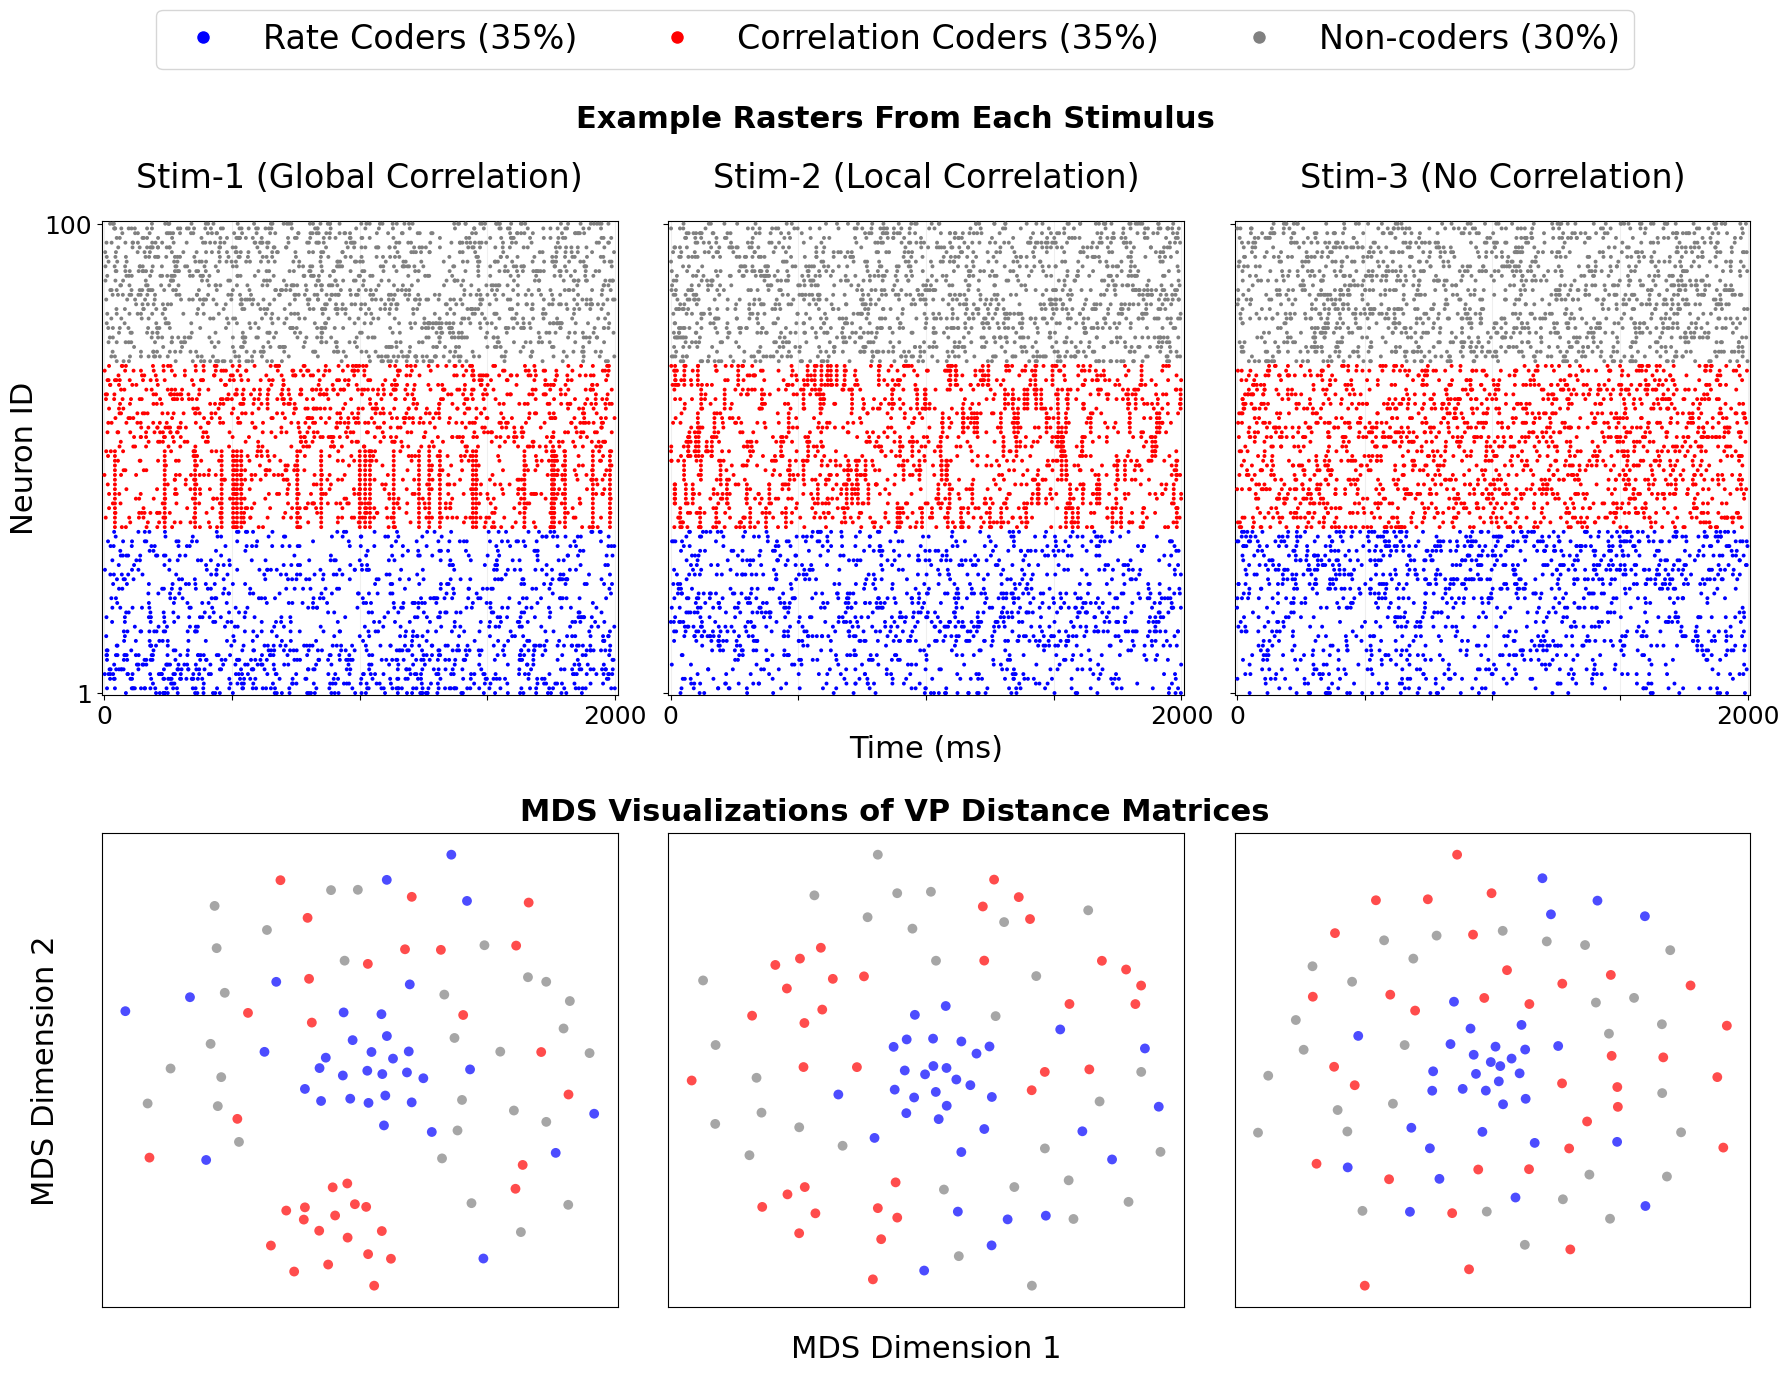

In [22]:
raster_MDS_plots(
    rate_pct=0.35,
    corr_pct=0.35,
    n_neurons=100,
    random_state=42,
    show_elevated_rate_region=False
)

# Plot with 1000 Neurons (not in the paper)

Total Neurons: 1000
 - Rate Coders (Blue): 350 (35.0%)
 - Correlation Coders (Red):  350 (35.0%)
 - Noise (Gray):       300 (30.0%)
 - Raster dot size:    1.00
 - MDS dot size:       12.68

Elevated firing-rate regions:
 - Stim-1: (1, 116)
 - Stim-2: (117, 232)
 - Stim-3: (233, 350)

Calculating VP matrix and MDS for Stim-1 (Global Correlation)...


/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Calculating VP matrix and MDS for Stim-2 (Local Correlation)...


/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


Calculating VP matrix and MDS for Stim-3 (No Correlation)...


/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


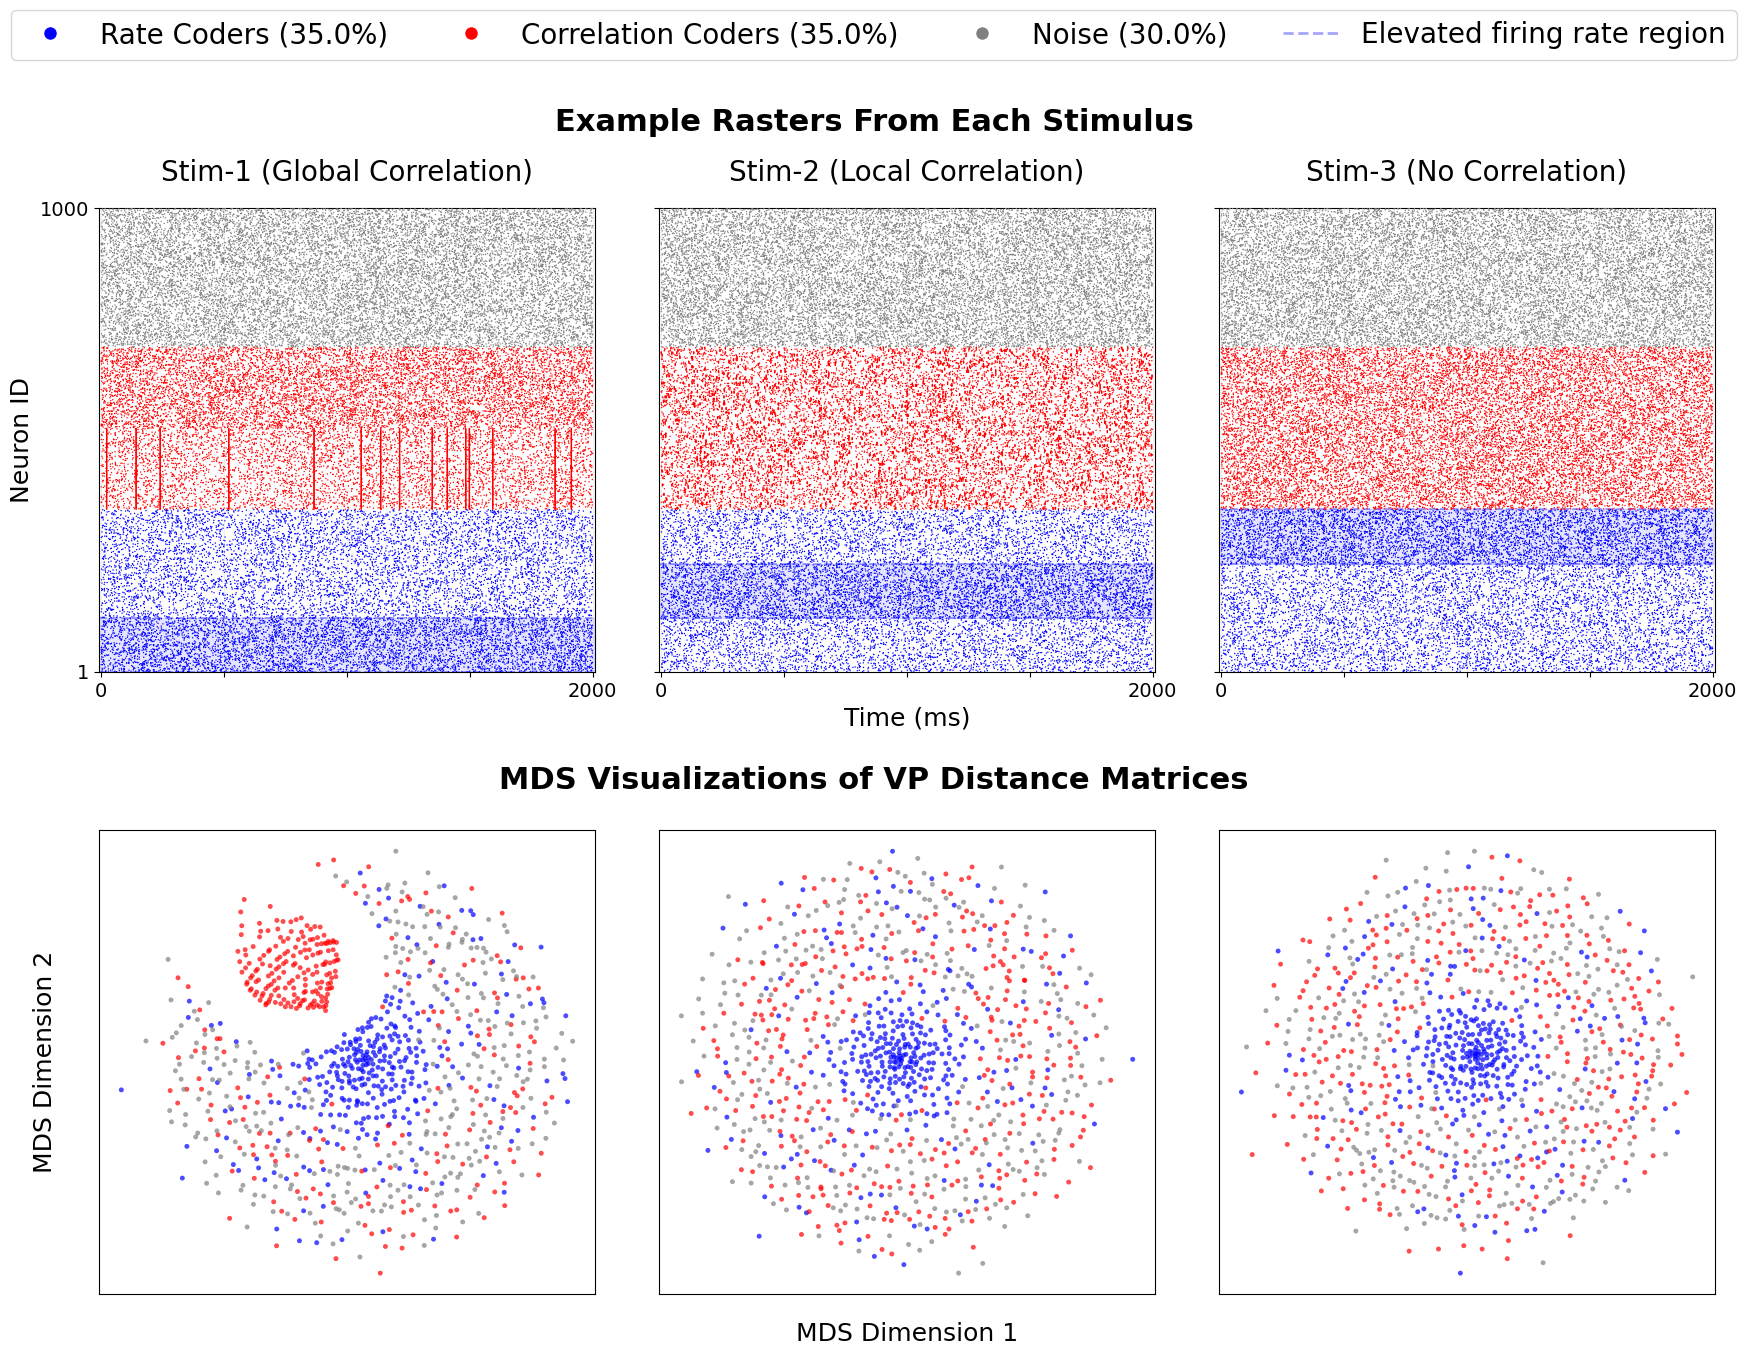

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.manifold import MDS

# --- Universal Font Controls ---
plt.rcParams.update({
    'axes.titlesize': 20,
    'axes.labelsize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 20,
    'axes.titlepad': 20 
})


def compute_raster_dot_size(n_neurons):
    """
    Adaptive raster marker size.

    Desired behavior:
        n_neurons = 100  -> size about 7-8
        n_neurons = 1000 -> size about 1
    """
    return float(np.clip(8 * (100 / n_neurons), 1.0, 8.0))


def compute_mds_dot_size(n_neurons):
    """
    Adaptive MDS marker size (larger scaling, capped at 50).

    Desired behavior:
        n_neurons = 100   -> ~50
        n_neurons = 1000  -> ~8–12
    """
    return float(np.clip(80 * (100 / n_neurons)**0.8, 6.0, 50.0))

def compute_rate_loud_regions(n_rate):
    """
    Compute elevated firing-rate regions dynamically.

    This matches the generation logic:

        chunk_size = n_rate // 3

        taste 0: i < chunk_size
        taste 1: chunk_size <= i < 2 * chunk_size
        taste 2: i >= 2 * chunk_size

    Returned neuron IDs are DISPLAYED IDs, so they start at 1.
    """

    if n_rate <= 0:
        return [None, None, None]

    chunk_size = n_rate // 3

    # If n_rate is very small, only the third region gets neurons,
    # matching the original generation logic.
    regions = []

    # Stim-1 / taste 0
    if chunk_size > 0:
        regions.append((1, chunk_size))
    else:
        regions.append(None)

    # Stim-2 / taste 1
    if chunk_size > 0:
        regions.append((chunk_size + 1, 2 * chunk_size))
    else:
        regions.append(None)

    # Stim-3 / taste 2, includes the remainder
    start_third = 2 * chunk_size + 1
    end_third = n_rate

    if start_third <= end_third:
        regions.append((start_third, end_third))
    else:
        regions.append(None)

    return regions


def get_dynamic_y_ticks(n_neurons):
    """
    Only show first and last neuron IDs.

    Examples:
        n_neurons = 100  -> [1, 100]
        n_neurons = 1000 -> [1, 1000]
    """
    if n_neurons <= 1:
        return [1]
    return [1, n_neurons]


def plot_raster_colored(
    raster,
    axes,
    n_rate,
    n_corr,
    n_noise,
    raster_marker='o',
    rate_color='blue',
    corr_color='red',
    noise_color='gray',
    rate_size=7,
    corr_size=7,
    noise_size=7,
    rate_alpha=1.0,
    corr_alpha=1.0,
    noise_alpha=1.0,
    loud_region=None,
    loud_region_color='blue',
    loud_region_alpha=0.10,
    loud_region_edge_alpha=0.35,
):
    """
    Colored raster plot.

    Internally, neuron indices are 0-based.
    In the plot, neuron IDs are displayed as 1-based:
        internal neuron 0 -> displayed neuron 1
        internal neuron 99 -> displayed neuron 100

    Neuron groups are assumed to be ordered as:
        1. Rate coders:        neurons 1, ..., n_rate
        2. Correlation coders: neurons n_rate+1, ..., n_rate+n_corr
        3. Noise neurons:      remaining neurons
    """

    # ------------------------------------------------------------
    # Highlight elevated firing-rate region
    # ------------------------------------------------------------
    if loud_region is not None:
        start_neuron, end_neuron = loud_region

        axes.axhspan(
            start_neuron - 0.5,
            end_neuron + 0.5,
            color=loud_region_color,
            alpha=loud_region_alpha,
            zorder=1
        )

        axes.axhline(
            start_neuron - 0.5,
            color=loud_region_color,
            alpha=loud_region_edge_alpha,
            linewidth=1.5,
            linestyle='--',
            zorder=2
        )

        axes.axhline(
            end_neuron + 0.5,
            color=loud_region_color,
            alpha=loud_region_edge_alpha,
            linewidth=1.5,
            linestyle='--',
            zorder=2
        )

    # ------------------------------------------------------------
    # Plot spikes by neuron type
    # ------------------------------------------------------------
    group_specs = [
        {
            "name": "Rate Coders",
            "start": 0,
            "end": n_rate,
            "color": rate_color,
            "size": rate_size,
            "alpha": rate_alpha,
        },
        {
            "name": "Correlation Coders",
            "start": n_rate,
            "end": n_rate + n_corr,
            "color": corr_color,
            "size": corr_size,
            "alpha": corr_alpha,
        },
        {
            "name": "Noise",
            "start": n_rate + n_corr,
            "end": n_rate + n_corr + n_noise,
            "color": noise_color,
            "size": noise_size,
            "alpha": noise_alpha,
        },
    ]

    for spec in group_specs:
        start = spec["start"]
        end = spec["end"]

        if end <= start:
            continue

        subraster = raster[start:end]
        local_neuron_ids, spike_times = np.where(subraster == 1)

        # Convert internal 0-based neuron index to displayed 1-based neuron ID
        neuron_ids_displayed = local_neuron_ids + start + 1

        axes.scatter(
            spike_times,
            neuron_ids_displayed,
            s=spec["size"],
            c=spec["color"],
            marker=raster_marker,
            alpha=spec["alpha"],
            linewidths=0,
            edgecolors='none',
            zorder=3
        )

    axes.set_ylim(0.5, raster.shape[0] + 0.5)
    axes.set_xlim(0, raster.shape[1])
    axes.grid(True, axis='x', alpha=0.2, zorder=0)


def raster_MDS_plots(rate_pct, corr_pct, n_neurons=100, random_state=42):
    n_rate = int(n_neurons * rate_pct)
    n_corr = int(n_neurons * corr_pct)
    n_noise = n_neurons - n_rate - n_corr 
    noise_pct = n_noise / n_neurons

    raster_dot_size = compute_raster_dot_size(n_neurons)
    mds_dot_size = compute_mds_dot_size(n_neurons)

    print(f"Total Neurons: {n_neurons}")
    print(f" - Rate Coders (Blue): {n_rate} ({rate_pct*100:.1f}%)")
    print(f" - Correlation Coders (Red):  {n_corr} ({corr_pct*100:.1f}%)")
    print(f" - Noise (Gray):       {n_noise} ({noise_pct*100:.1f}%)")
    print(f" - Raster dot size:    {raster_dot_size:.2f}")
    print(f" - MDS dot size:       {mds_dot_size:.2f}\n")

    # Generate Dataset
    X, y = generate_hybrid_dataset(
        rate_percent=rate_pct,
        corr_percent=corr_pct,
        n_neurons=n_neurons,
        random_state=random_state
    )
    
    # Representative rasters
    indices = [1, 31, 62]  # Stim-1, Stim-2, Stim-3

    titles = [
        'Stim-1 (Global Correlation)',
        'Stim-2 (Local Correlation)',
        'Stim-3 (No Correlation)'
    ]

    # Dynamic elevated firing-rate regions
    rate_loud_regions = compute_rate_loud_regions(n_rate)

    print("Elevated firing-rate regions:")
    for stim_idx, region in enumerate(rate_loud_regions, start=1):
        print(f" - Stim-{stim_idx}: {region}")
    print()

    # MDS colors
    colors = (['blue'] * n_rate) + (['red'] * n_corr) + (['gray'] * n_noise)

    # Initialize MDS 
    mds = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        n_jobs=-1
    )

    fig, axes = plt.subplots(2, 3, figsize=(18, 14))

    for col, idx in enumerate(indices):
        raster = X[idx]
        
        # -----------------------------------------
        # ROW 1: COLORED RASTER PLOTS
        # -----------------------------------------
        ax_raster = axes[0, col]

        plot_raster_colored(
            raster,
            axes=ax_raster,
            n_rate=n_rate,
            n_corr=n_corr,
            n_noise=n_noise,

            # Adaptive appearance controls
            raster_marker='o',
            rate_size=raster_dot_size,
            corr_size=raster_dot_size,
            noise_size=raster_dot_size,
            rate_alpha=1.0,
            corr_alpha=1.0,
            noise_alpha=1.0,

            # Dynamic elevated-rate highlight
            loud_region=rate_loud_regions[col],
            loud_region_color='blue',
            loud_region_alpha=0.10,
            loud_region_edge_alpha=0.35,
        )
        
        ax_raster.set_title(titles[col])
        ax_raster.set_xticks([0, 500, 1000, 1500, 2000])
        ax_raster.set_xticklabels(['0', '', '', '', '2000'])
        ax_raster.set_xlim(-10, 2010)
        ax_raster.set_ylim(0.5, n_neurons + 0.5)
        
        if col == 1:
            ax_raster.set_xlabel("Time (ms)")
        else:
            ax_raster.set_xlabel("")
        
        # Dynamic y-ticks: only first and last neuron ID
        y_ticks = get_dynamic_y_ticks(n_neurons)

        if col == 0:
            ax_raster.set_ylabel("Neuron ID", fontweight='normal')
            ax_raster.set_yticks(y_ticks)
            ax_raster.set_yticklabels([str(tick) for tick in y_ticks])
        else:
            ax_raster.set_ylabel("")
            ax_raster.set_yticks(y_ticks)
            plt.setp(ax_raster.get_yticklabels(), visible=False)

        # -----------------------------------------
        # ROW 2: MDS PLOTS
        # -----------------------------------------
        ax_mds = axes[1, col]
        
        print(f"Calculating VP matrix and MDS for {titles[col]}...")
        vp_dm = VP_trivial(raster)
        embedding = mds.fit_transform(vp_dm)
        
        ax_mds.scatter(
            embedding[:, 0],
            embedding[:, 1],
            c=colors,
            s=mds_dot_size,
            alpha=0.7,
            edgecolors='none'
        )
        
        ax_mds.set_title("")
        ax_mds.set_xticks([])
        ax_mds.set_yticks([])
        
        if col == 1:
            ax_mds.set_xlabel('MDS Dimension 1', labelpad=20)
        else:
            ax_mds.set_xlabel("")
        
        if col == 0:
            ax_mds.set_ylabel('MDS Dimension 2', fontweight='normal', labelpad=30)
        else:
            ax_mds.set_ylabel("")
            plt.setp(ax_mds.get_yticklabels(), visible=False)

    # -----------------------------------------
    # ROW TITLES, LEGEND & CLEANUP
    # -----------------------------------------
    fig.text(
        0.5,
        0.90,
        "Example Rasters From Each Stimulus",
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=22
    )

    fig.text(
        0.5,
        0.43,
        "MDS Visualizations of VP Distance Matrices",
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=22
    )

    legend_elements = [
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Rate Coders ({rate_pct*100:.1f}%)',
            markerfacecolor='blue',
            markersize=10
        ),
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Correlation Coders ({corr_pct*100:.1f}%)',
            markerfacecolor='red',
            markersize=10
        ),
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=f'Noise ({noise_pct*100:.1f}%)',
            markerfacecolor='gray',
            markersize=10
        ),
        Line2D(
            [0], [0],
            color='blue',
            alpha=0.35,
            linestyle='--',
            linewidth=2,
            label='Elevated firing rate region'
        )
    ]
    
    fig.legend(
        handles=legend_elements,
        loc='upper center',
        ncol=4,
        bbox_to_anchor=(0.5, 0.99)
    )

    plt.tight_layout(rect=[0, 0, 1, 0.90], h_pad=3.0) 
    
    plt.savefig(f'Hybrid-coding-example-figure_{n_neurons}_neurons.pdf', bbox_inches='tight')
    plt.show()


# Example plot
raster_MDS_plots(
    rate_pct=0.35,
    corr_pct=0.35,
    n_neurons=1000,
    random_state=42
)

# Results with 1000 neurons (these are some extra analyses. Paper uses 100 neurons.)

In [ ]:
import time
rate_pct_list = [0.0, # 0 %
                 0.01, # 1%
                 0.02, # 2%
                 0.03, # 3%
                 0.04, # 4%
                 0.05, # 5%
                 0.1, # 10%
                 0.2, # 20%
                 0.3, # 30%
                 0.4, # 40%
                 0.5, # 50%
                 0.6, # 60%
                 ]



results = []
n_neurons = 1000

for rate_pct in tqdm(rate_pct_list, desc="Running rate_pct experiments"):
    corr_pct = 0.70 - rate_pct
    print(f"\nGenerating mix -> Rate: {rate_pct*100:.1f}%, Correlation: {corr_pct*100:.1f}%")

    # Generate the data
    X, y = generate_hybrid_dataset(rate_percent=rate_pct, corr_percent=corr_pct, n_neurons = 1000, random_state = 42)

    # TDA Original
    print("  Running TDA...")
    tda_start = time.perf_counter()
    tda_acc = tda_rhv(X, y)
    tda_runtime = time.perf_counter() - tda_start
    print(f"  TDA done | Acc: {tda_acc:.4f} | Time: {tda_runtime:.2f} s")

    # SVM Pure Rate
    print("  Running SVM...")
    svm_start = time.perf_counter()
    svm_acc, _, _ = svm_smoothed_rasters(X, y)
    svm_runtime = time.perf_counter() - svm_start
    print(f"  SVM done | Acc: {svm_acc:.4f} | Time: {svm_runtime:.2f} s")

    # Save the results
    results.append({
        'Rate_Percent': rate_pct,
        'Corr_Percent': corr_pct,
        'TDA_Acc': tda_acc,
        'TDA_Runtime_Sec': tda_runtime,
        'SVM_Acc': svm_acc,
        'SVM_Runtime_Sec': svm_runtime
    })
    

Running rate_pct experiments:   0%|          | 0/12 [00:00<?, ?it/s]


Generating mix -> Rate: 0.0%, Correlation: 70.0%
  Running TDA...


Building BDM: 100%|██████████| 90/90 [00:05<00:00, 16.72it/s]


  TDA done | Acc: 1.0000 | Time: 624.04 s
  Running SVM...


Running rate_pct experiments:   8%|▊         | 1/12 [12:30<2:17:35, 750.53s/it]

  SVM done | Acc: 0.2852 | Time: 124.73 s

Generating mix -> Rate: 1.0%, Correlation: 69.0%
  Running TDA...


... (40 outputs left out)

Building BDM: 100%|██████████| 90/90 [00:14<00:00,  6.21it/s]


  TDA done | Acc: 0.4000 | Time: 706.65 s
  Running SVM...


Running rate_pct experiments: 100%|██████████| 12/12 [3:25:46<00:00, 1028.84s/it]

  SVM done | Acc: 1.0000 | Time: 266.37 s


In [ ]:
import pandas as pd
# save results
# df_results = pd.DataFrame(results)

# df_results.to_csv('hybrid_experiment_results.csv', index=False)

df_results = pd.read_csv('hybrid_experiment_results.csv')
df_results.head()

,Rate_Percent,Corr_Percent,TDA_Acc,TDA_Runtime_Sec,SVM_Acc,SVM_Runtime_Sec
0,0.00,0.70,1.000000,624.041495,0.285185,124.725696
1,0.01,0.69,0.988889,632.707229,0.574074,111.626549
2,0.02,0.68,1.000000,638.054790,0.825926,127.074838
3,0.03,0.67,0.988889,636.957672,0.918519,124.229747
4,0.04,0.66,0.983333,632.795535,0.964815,116.558600


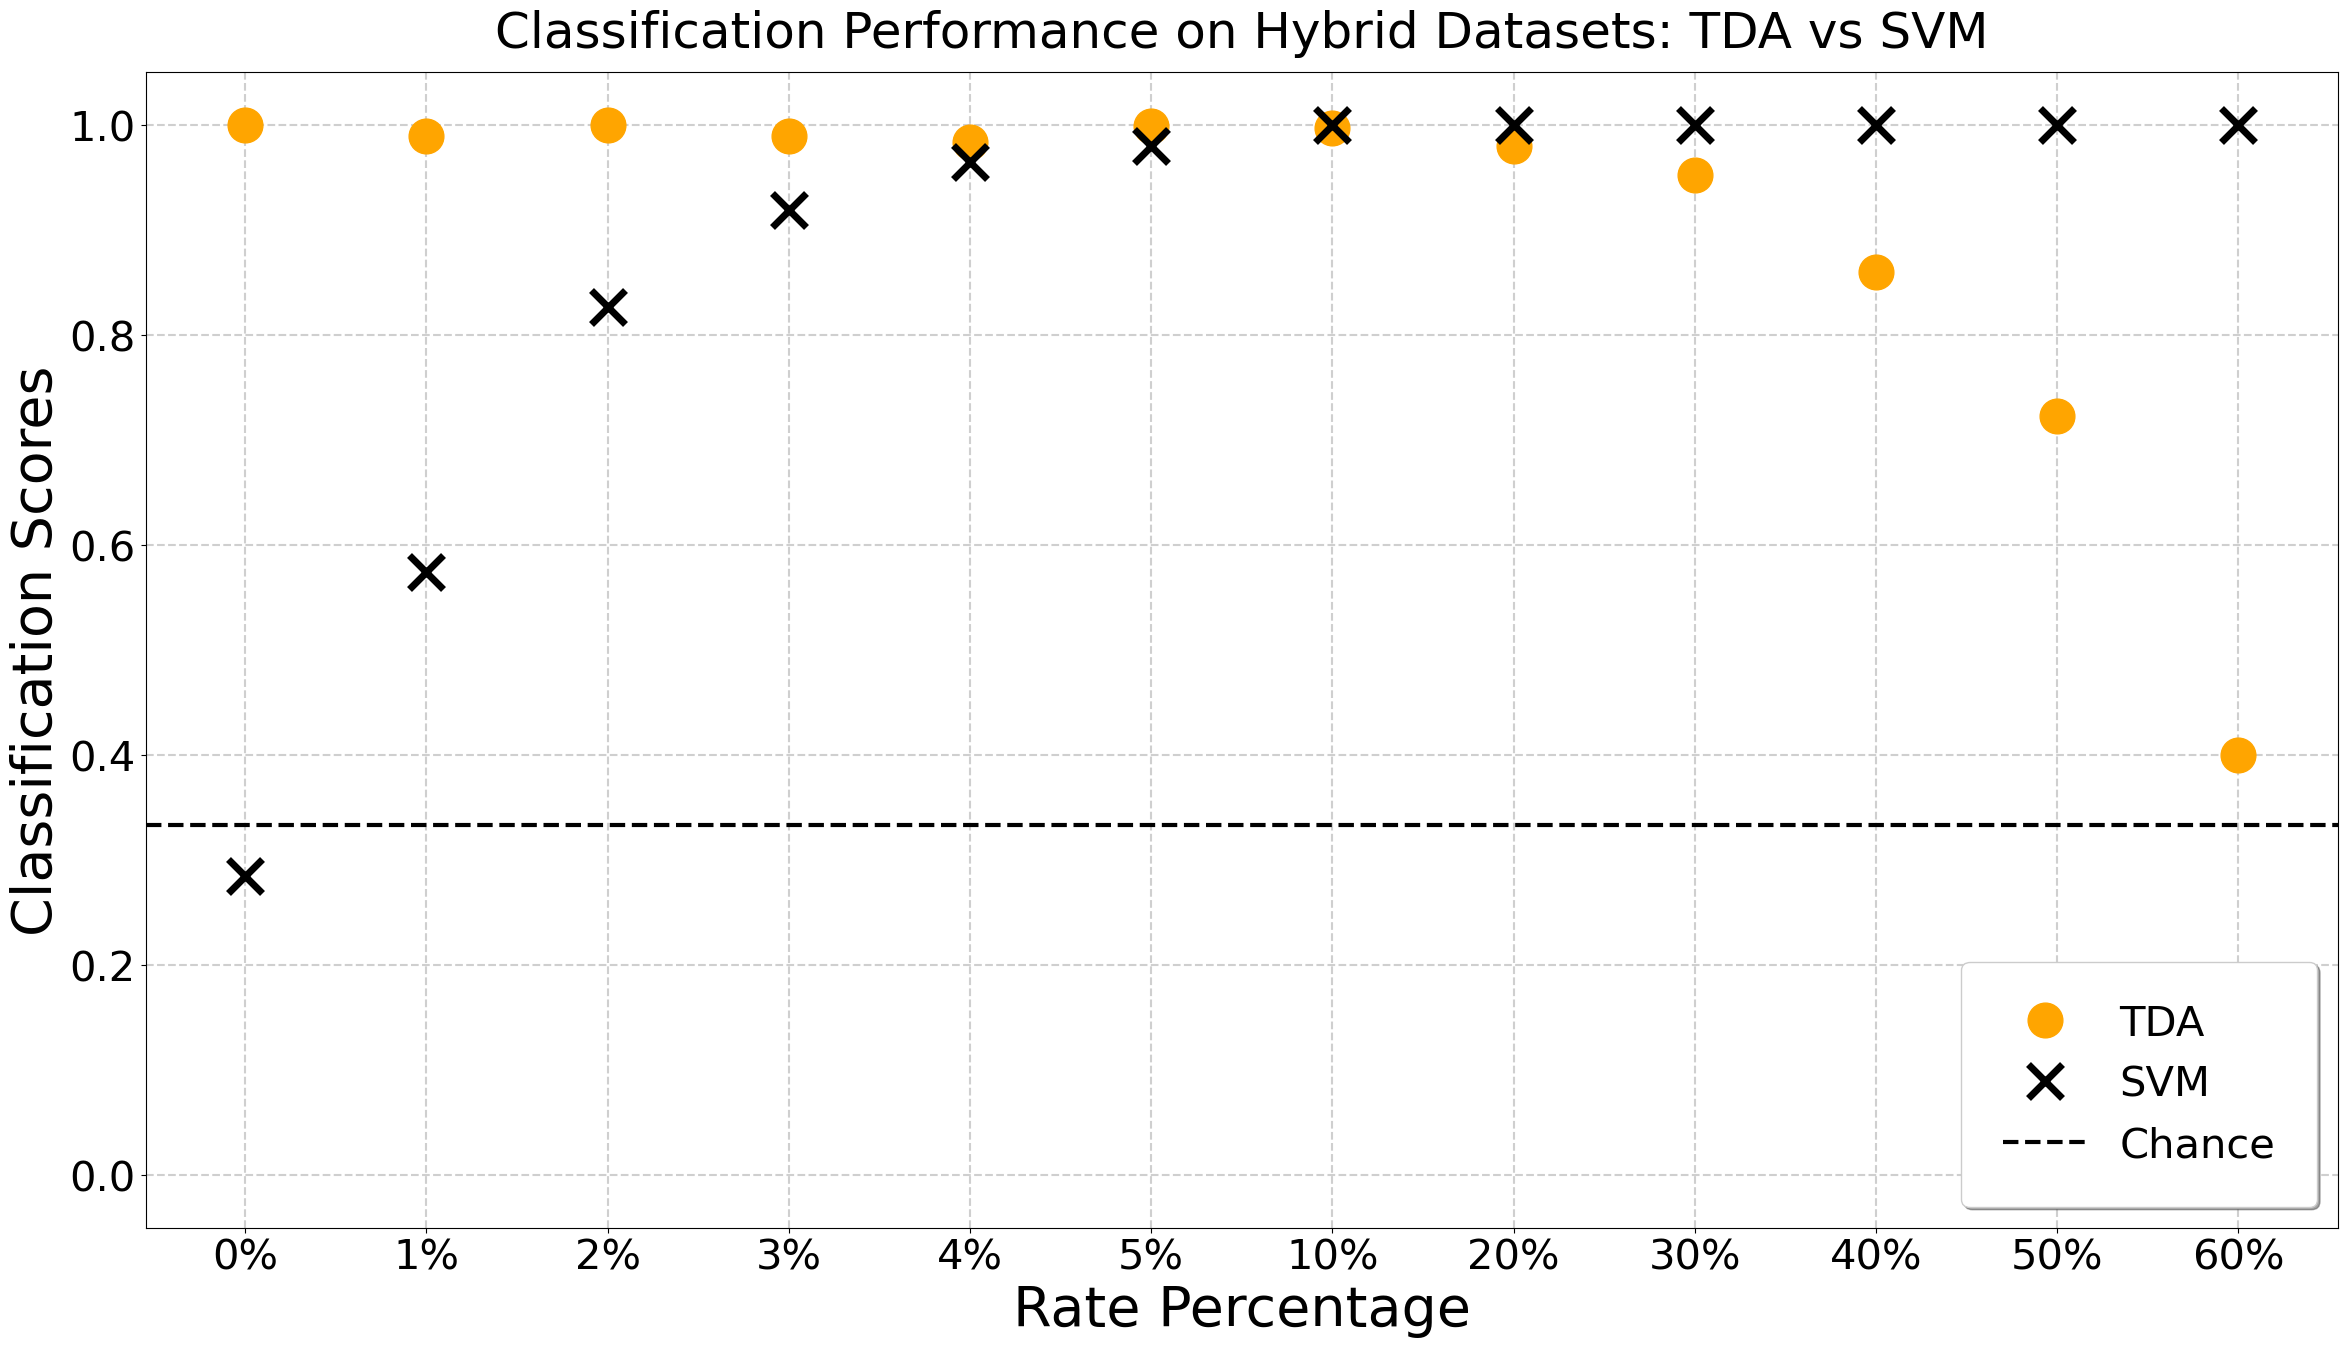

In [ ]:

df_results = df_results.sort_values(by='Rate_Percent').reset_index(drop=True)

import matplotlib.pyplot as plt
plt.rcParams.update({
    # --- Global Font Properties ---
    'font.family': 'sans-serif',    # Base font family (e.g., 'sans-serif', 'serif', 'monospace')
    'font.size': 24,                # Global default font size (affects everything not explicitly set below)
    
    # --- Figure & Subplot Titles ---
    'figure.titlesize': 36,         # Size of the overall figure title (plt.suptitle)
    'figure.titleweight': 'bold',   # Font weight of the overall figure title
    'axes.titlesize': 36,           # Size of individual subplot titles (ax.set_title)
    'axes.titleweight': 'normal',   # Font weight of subplot titles
    
    # --- Axis Labels (X and Y titles) ---
    'axes.labelsize': 40,           # Size of x and y axis labels (ax.set_xlabel, ax.set_ylabel)
    'axes.labelweight': 'normal',     # Font weight of axis labels
    
    # --- Tick Labels (The numbers/text on the axes) ---
    'xtick.labelsize': 30,          # Font size of x-axis tick numbers
    'ytick.labelsize': 30,          # Font size of y-axis tick numbers
    
    # --- Legend ---
    'legend.fontsize': 30,          # Font size of the text inside the legend
    'legend.title_fontsize': 30,    # Font size of the legend's title

    # --- pad---
    'axes.titlepad': 18
})

plt.figure(figsize=(24, 14)) # Large canvas

# Plot TDA (Orange Dots)
plt.plot(df_results.index, df_results['TDA_Acc'], 'o', 
         color='orange', label='TDA', markersize=25)

# Plot SVM (Black Plus Signs)
plt.plot(df_results.index, df_results['SVM_Acc'], 'x', 
         color='black', label='SVM', markersize=25, mew=5)

# Random Guessing line
plt.axhline(y=1/3, color='black', linestyle='--',lw = 3, label = 'Chance')

# Create custom x-tick labels: (Rate %, Sync %)
x_labels = [f"{int(round(r*100, 1))}%" for r in df_results['Rate_Percent']]

plt.xticks(range(len(df_results)), x_labels, rotation=0)

# Formatting with large labels
plt.xlabel("Rate Percentage")
plt.ylabel("Classification Scores")
plt.title("Classification Performance on Hybrid Datasets: TDA vs SVM")
plt.ylim(-0.05, 1.05)

# Enhanced Legend
plt.legend(loc='lower right', frameon=True, shadow=True, borderpad=1)
plt.grid(True, linestyle='--', alpha=0.6, linewidth=1.5)

plt.tight_layout()
plt.savefig('hybrid_datasets_tda_vs_svm.pdf')
plt.show()

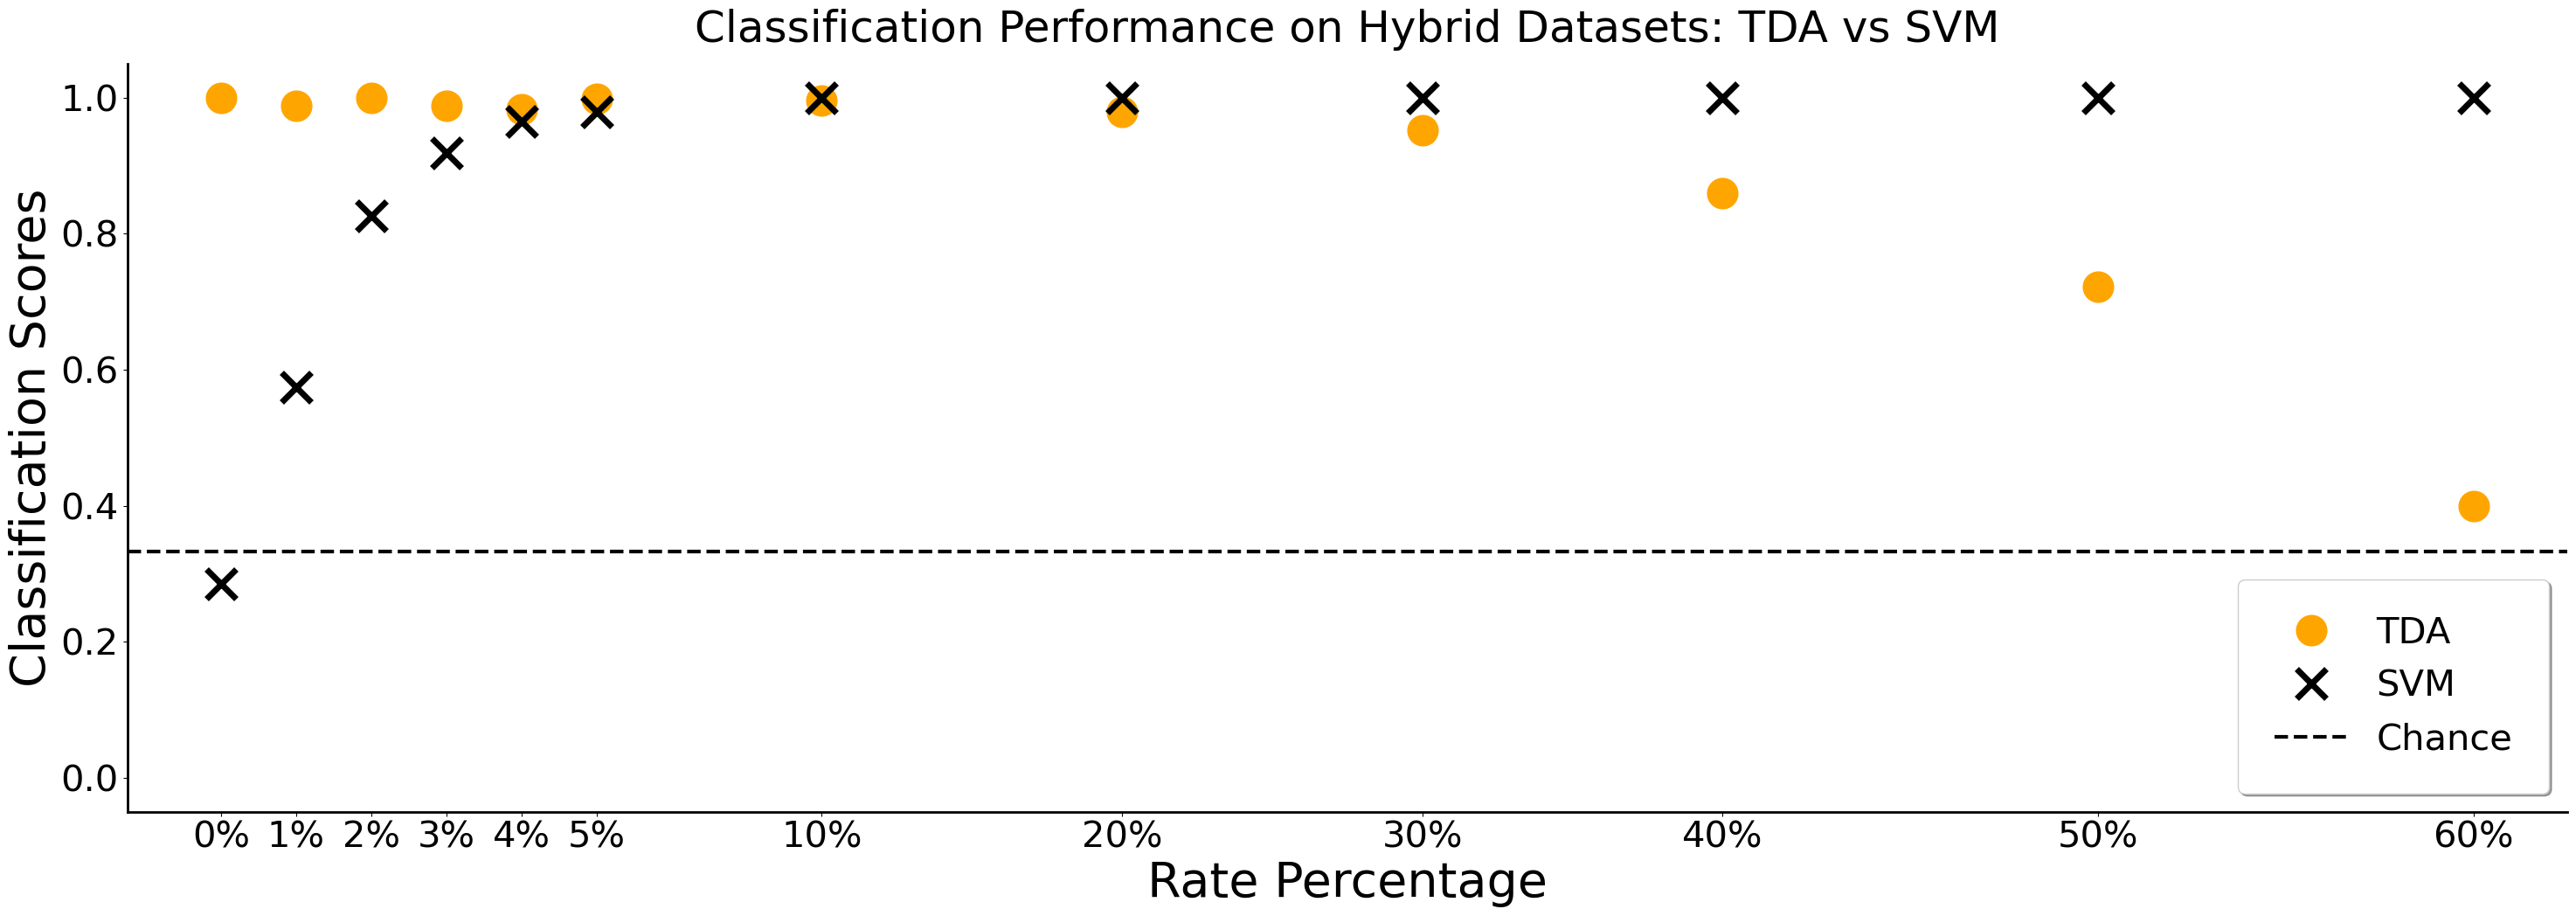

In [ ]:
# Same figure as above but x-axis more adapted. Refined figure.
# 1000 neurons

df_results = df_results.sort_values(by='Rate_Percent').reset_index(drop=True)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 24,
    'figure.titlesize': 36,
    'figure.titleweight': 'bold',
    'axes.titlesize': 36,
    'axes.titleweight': 'normal',
    'axes.labelsize': 40,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 30,
    'ytick.labelsize': 30,
    'legend.fontsize': 30,
    'legend.title_fontsize': 30,
    'axes.titlepad': 18
})

fig, ax = plt.subplots(figsize=(30, 11))

# Actual rate percentages
rate_vals = 100 * df_results['Rate_Percent'].to_numpy()

# ------------------------------------------------------------
# Manual x-position control
# ------------------------------------------------------------
# By default, each point is plotted at its actual percentage.
# Change these numbers to manually adjust horizontal placement.
#
# Example:
#   0% stays at 0
#   1% displayed at 2
#   2% displayed at 4
#   ...
# Labels will still show the original rate percentages.
# ------------------------------------------------------------

manual_x_positions = {
    0: 0,
    1: 2,
    2: 4,
    3: 6,
    4: 8,
    5: 10,
    10: 16,
    20: 24,
    30: 32,
    40: 40,
    50: 50,
    60: 60,
}

x_plot = np.array([
    manual_x_positions.get(int(round(r)), r)
    for r in rate_vals
])

# Plot TDA
ax.plot(
    x_plot,
    df_results['TDA_Acc'],
    'o',
    color='orange',
    label='TDA',
    markersize=25,
    clip_on=True
)

# Plot SVM
ax.plot(
    x_plot,
    df_results['SVM_Acc'],
    'x',
    color='black',
    label='SVM',
    markersize=25,
    mew=5,
    clip_on=True
)

# Chance line
ax.axhline(
    y=1/3,
    color='black',
    linestyle='--',
    lw=3,
    label='Chance'
)

# Tick labels: placed at manual positions, labeled by true rate percentages
ax.set_xticks(x_plot)
ax.set_xticklabels([f"{int(round(r))}%" for r in rate_vals], rotation=0)

# Add horizontal padding so boundary markers do not leak out
x_pad = 2.5
ax.set_xlim(x_plot.min() - x_pad, x_plot.max() + x_pad)

ax.set_xlabel("Rate Percentage")
ax.set_ylabel("Classification Scores")
ax.set_title("Classification Performance on Hybrid Datasets: TDA vs SVM")
ax.set_ylim(-0.05, 1.05)

ax.legend(loc='lower right', frameon=True, shadow=True, borderpad=1)
# ax.grid(True, linestyle='--', alpha=0.6, linewidth=1.5)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep left and bottom spines
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# Optional: make ticks only appear on left and bottom
ax.yaxis.set_ticks_position('left')
ax.xaxis.set_ticks_position('bottom')

plt.tight_layout()
plt.savefig('hybrid_datasets_tda_vs_svm_1000_neurons.pdf')
plt.show()